# Machine Learning Engineer Nanodegree
## Supervised Learning
## Project: Finding Donors for *CharityML*

Welcome to the second project of the Machine Learning Engineer Nanodegree! In this notebook, some template code has already been provided for you, and it will be your job to implement the additional functionality necessary to successfully complete this project. Sections that begin with **'Implementation'** in the header indicate that the following block of code will require additional functionality which you must provide. Instructions will be provided for each section and the specifics of the implementation are marked in the code block with a `'TODO'` statement. Please be sure to read the instructions carefully!

In addition to implementing code, there will be questions that you must answer which relate to the project and your implementation. Each section where you will answer a question is preceded by a **'Question X'** header. Carefully read each question and provide thorough answers in the following text boxes that begin with **'Answer:'**.

>**Python version:** 3.14.7, with scikit-learn 1.9, pandas 3.0 and NumPy 2.5. The original template targeted Python 2.7 and scikit-learn 0.16, so a few imports have been moved to where those functions live today (`sklearn.cross_validation` became `sklearn.model_selection`, for instance). The logic itself is unchanged.

## Getting Started

In this project, you will employ several supervised algorithms of your choice to accurately model individuals' income using data collected from the 1994 U.S. Census. You will then choose the best candidate algorithm from preliminary results and further optimize this algorithm to best model the data. Your goal with this implementation is to construct a model that accurately predicts whether an individual makes more than $50,000. This sort of task can arise in a non-profit setting, where organizations survive on donations.  Understanding an individual's income can help a non-profit better understand how large of a donation to request, or whether or not they should reach out to begin with.  While it can be difficult to determine an individual's general income bracket directly from public sources, we can (as we will see) infer this value from other publically available features. 

The dataset for this project originates from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Census+Income). The datset was donated by Ron Kohavi and Barry Becker, after being published in the article _"Scaling Up the Accuracy of Naive-Bayes Classifiers: A Decision-Tree Hybrid"_. You can find the article by Ron Kohavi [online](https://www.aaai.org/Papers/KDD/1996/KDD96-033.pdf). The data we investigate here consists of small changes to the original dataset, such as removing the `'fnlwgt'` feature and records with missing or ill-formatted entries.

----
## Exploring the Data
Run the code cell below to load necessary Python libraries and load the census data. Note that the last column from this dataset, `'income'`, will be our target label (whether an individual makes more than, or at most, $50,000 annually). All other columns are features about each individual in the census database.

In [1]:
# Import libraries necessary for this project
import warnings

import numpy as np
import pandas as pd
from time import time
from IPython.display import display # Allows the use of display() for DataFrames

# Import supplementary visualization code visuals.py
import visuals as vs
from visuals import distribution
# Pretty display for notebooks
%matplotlib inline

# visuals.py suppresses matplotlib's own UserWarnings, but on current matplotlib
# this one is raised from visuals.py itself, so it slips past that filter.
warnings.filterwarnings('ignore', message='.*non-interactive.*')

# Load the Census dataset
data = pd.read_csv("census.csv")


# Success - Display the first record
display(data.head(n=1))

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K



<div>
    <button onclick="like()" style="padding: 10px 20px; margin-right: 10px;">👍 Like</button>
   
</div>



### Implementation: Data Exploration
A cursory investigation of the dataset will determine how many individuals fit into either group, and will tell us about the percentage of these individuals making more than \$50,000. In the code cell below, you will need to compute the following:
- The total number of records, `'n_records'`
- The number of individuals making more than \$50,000 annually, `'n_greater_50k'`.
- The number of individuals making at most \$50,000 annually, `'n_at_most_50k'`.
- The percentage of individuals making more than \$50,000 annually, `'greater_percent'`.

** HINT: ** You may need to look at the table above to understand how the `'income'` entries are formatted. 

In [2]:
# Total number of records
n_records = data.shape[0]

# Number of records where individual's income is more than $50,000
n_greater_50k = data.query("income == '>50K'").shape[0]

# Number of records where individual's income is at most $50,000
n_at_most_50k = data.query("income == '<=50K'").shape[0]

# Percentage of individuals whose income is more than $50,000
greater_percent = 100.0 * n_greater_50k / n_records

# Print the results
print("Total number of records: {}".format(n_records))
print("Individuals making more than $50,000: {}".format(n_greater_50k))
print("Individuals making at most $50,000: {}".format(n_at_most_50k))
print("Percentage of individuals making more than $50,000: {}%".format(greater_percent))

Total number of records: 45222
Individuals making more than $50,000: 11208
Individuals making at most $50,000: 34014
Percentage of individuals making more than $50,000: 24.78439697492371%


<div>
    <button onclick="dislike()" style="padding: 10px 20px;">👎 Dislike</button>

</div>

### where your output code here

** Featureset Exploration **

* **age**: continuous. 
* **workclass**: Private, Self-emp-not-inc, Self-emp-inc, Federal-gov, Local-gov, State-gov, Without-pay, Never-worked. 
* **education**: Bachelors, Some-college, 11th, HS-grad, Prof-school, Assoc-acdm, Assoc-voc, 9th, 7th-8th, 12th, Masters, 1st-4th, 10th, Doctorate, 5th-6th, Preschool. 
* **education-num**: continuous. 
* **marital-status**: Married-civ-spouse, Divorced, Never-married, Separated, Widowed, Married-spouse-absent, Married-AF-spouse. 
* **occupation**: Tech-support, Craft-repair, Other-service, Sales, Exec-managerial, Prof-specialty, Handlers-cleaners, Machine-op-inspct, Adm-clerical, Farming-fishing, Transport-moving, Priv-house-serv, Protective-serv, Armed-Forces. 
* **relationship**: Wife, Own-child, Husband, Not-in-family, Other-relative, Unmarried. 
* **race**: Black, White, Asian-Pac-Islander, Amer-Indian-Eskimo, Other. 
* **sex**: Female, Male. 
* **capital-gain**: continuous. 
* **capital-loss**: continuous. 
* **hours-per-week**: continuous. 
* **native-country**: United-States, Cambodia, England, Puerto-Rico, Canada, Germany, Outlying-US(Guam-USVI-etc), India, Japan, Greece, South, China, Cuba, Iran, Honduras, Philippines, Italy, Poland, Jamaica, Vietnam, Mexico, Portugal, Ireland, France, Dominican-Republic, Laos, Ecuador, Taiwan, Haiti, Columbia, Hungary, Guatemala, Nicaragua, Scotland, Thailand, Yugoslavia, El-Salvador, Trinadad&Tobago, Peru, Hong, Holand-Netherlands.

----
## Preparing the Data
Before data can be used as input for machine learning algorithms, it often must be cleaned, formatted, and restructured — this is typically known as **preprocessing**. Fortunately, for this dataset, there are no invalid or missing entries we must deal with, however, there are some qualities about certain features that must be adjusted. This preprocessing can help tremendously with the outcome and predictive power of nearly all learning algorithms.

### Transforming Skewed Continuous Features
A dataset may sometimes contain at least one feature whose values tend to lie near a single number, but will also have a non-trivial number of vastly larger or smaller values than that single number.  Algorithms can be sensitive to such distributions of values and can underperform if the range is not properly normalized. With the census dataset two features fit this description: '`capital-gain'` and `'capital-loss'`. 

Run the code cell below to plot a histogram of these two features. Note the range of the values present and how they are distributed.

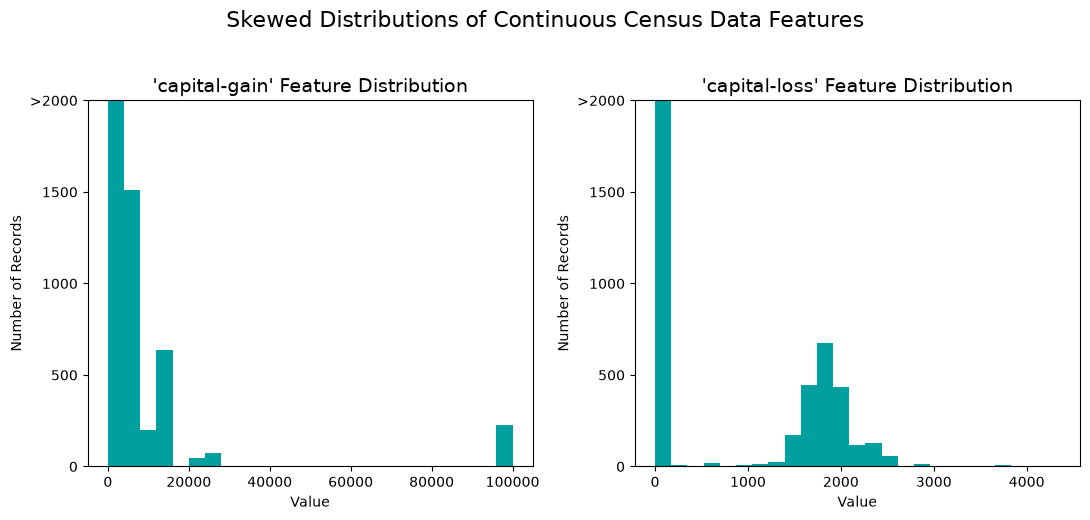

In [3]:
# Split the data into features and target label
income_raw = data['income']
features_raw = data.drop('income', axis = 1)

# Visualize skewed continuous features of original data
vs.distribution(data)

For highly-skewed feature distributions such as `'capital-gain'` and `'capital-loss'`, it is common practice to apply a <a href="https://en.wikipedia.org/wiki/Data_transformation_(statistics)">logarithmic transformation</a> on the data so that the very large and very small values do not negatively affect the performance of a learning algorithm. Using a logarithmic transformation significantly reduces the range of values caused by outliers. Care must be taken when applying this transformation however: The logarithm of `0` is undefined, so we must translate the values by a small amount above `0` to apply the the logarithm successfully.

Run the code cell below to perform a transformation on the data and visualize the results. Again, note the range of values and how they are distributed. 


<div>
    <button onclick="like()" style="padding: 10px 20px; margin-right: 10px;">👍 Like</button>
   
</div>

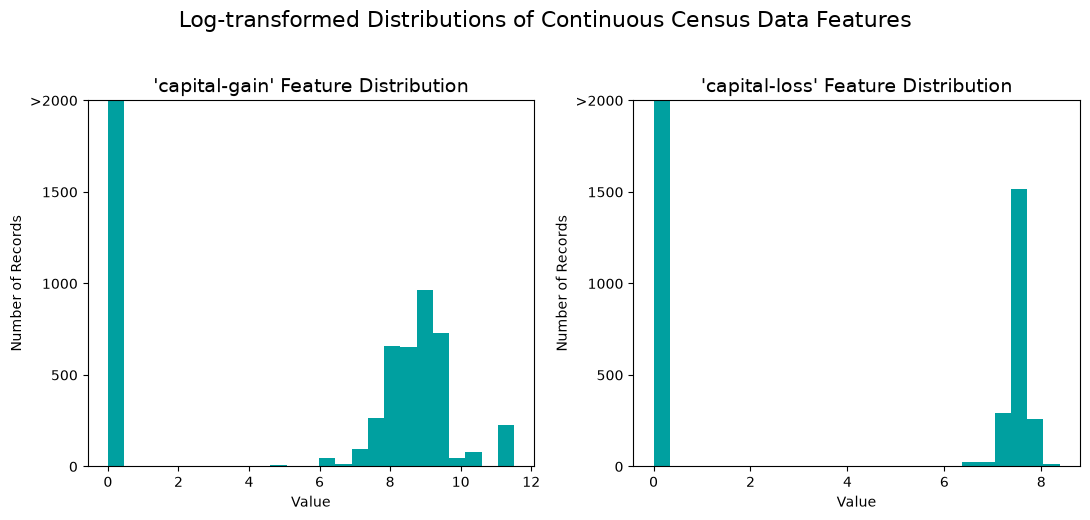

In [4]:
# Log-transform the skewed features
skewed = ['capital-gain', 'capital-loss']
features_log_transformed = pd.DataFrame(data = features_raw)
features_log_transformed[skewed] = features_raw[skewed].apply(lambda x: np.log(x + 1))

# Visualize the new log distributions
vs.distribution(features_log_transformed, transformed = True)

### Normalizing Numerical Features
In addition to performing transformations on features that are highly skewed, it is often good practice to perform some type of scaling on numerical features. Applying a scaling to the data does not change the shape of each feature's distribution (such as `'capital-gain'` or `'capital-loss'` above); however, normalization ensures that each feature is treated equally when applying supervised learners. Note that once scaling is applied, observing the data in its raw form will no longer have the same original meaning, as exampled below.

Run the code cell below to normalize each numerical feature. We will use [`sklearn.preprocessing.MinMaxScaler`](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) for this.

In [5]:
# Import sklearn.preprocessing.StandardScaler
from sklearn.preprocessing import MinMaxScaler

# Initialize a scaler, then apply it to the features
scaler = MinMaxScaler() # default=(0, 1)
numerical = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

features_log_minmax_transform = pd.DataFrame(data = features_log_transformed)
features_log_minmax_transform[numerical] = scaler.fit_transform(features_log_transformed[numerical])

# Show an example of a record with scaling applied
display(features_log_minmax_transform.head(n = 5))

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,0.301370,State-gov,Bachelors,0.800000,Never-married,Adm-clerical,Not-in-family,White,Male,0.667492,0.0,0.397959,United-States
1,0.452055,Self-emp-not-inc,Bachelors,0.800000,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.000000,0.0,0.122449,United-States
2,0.287671,Private,HS-grad,0.533333,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.000000,0.0,0.397959,United-States
3,0.493151,Private,11th,0.400000,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.000000,0.0,0.397959,United-States
4,0.150685,Private,Bachelors,0.800000,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.000000,0.0,0.397959,Cuba



<div>
    <button onclick="like()" style="padding: 10px 20px; margin-right: 10px;">👍 Like</button>
   
</div>

### Implementation: Data Preprocessing

From the table in **Exploring the Data** above, we can see there are several features for each record that are non-numeric. Typically, learning algorithms expect input to be numeric, which requires that non-numeric features (called *categorical variables*) be converted. One popular way to convert categorical variables is by using the **one-hot encoding** scheme. One-hot encoding creates a _"dummy"_ variable for each possible category of each non-numeric feature. For example, assume `someFeature` has three possible entries: `A`, `B`, or `C`. We then encode this feature into `someFeature_A`, `someFeature_B` and `someFeature_C`.

|   | someFeature |                    | someFeature_A | someFeature_B | someFeature_C |
| :-: | :-: |                            | :-: | :-: | :-: |
| 0 |  B  |  | 0 | 1 | 0 |
| 1 |  C  | ----> one-hot encode ----> | 0 | 0 | 1 |
| 2 |  A  |  | 1 | 0 | 0 |

Additionally, as with the non-numeric features, we need to convert the non-numeric target label, `'income'` to numerical values for the learning algorithm to work. Since there are only two possible categories for this label ("<=50K" and ">50K"), we can avoid using one-hot encoding and simply encode these two categories as `0` and `1`, respectively. In code cell below, you will need to implement the following:
 - Use [`pandas.get_dummies()`](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.get_dummies.html?highlight=get_dummies#pandas.get_dummies) to perform one-hot encoding on the `'features_log_minmax_transform'` data.
 - Convert the target label `'income_raw'` to numerical entries.
   - Set records with "<=50K" to `0` and records with ">50K" to `1`.

In [6]:
# One-hot encode the categorical columns; the numeric ones are left alone
features_final = pd.get_dummies(features_log_minmax_transform)

# The label only has two possible values, so 0/1 is enough - no need to one-hot it
income = income_raw.map({'<=50K': 0, '>50K': 1})

# Print the number of features after one-hot encoding
encoded = list(features_final.columns)
print("{} total features after one-hot encoding.".format(len(encoded)))

103 total features after one-hot encoding.


<div>
    <button onclick="dislike()" style="padding: 10px 20px;">👎 Dislike</button>

</div>

### Shuffle and Split Data
Now all _categorical variables_ have been converted into numerical features, and all numerical features have been normalized. As always, we will now split the data (both features and their labels) into training and test sets. 80% of the data will be used for training and 20% for testing.

Run the code cell below to perform this split.

In [7]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the 'features' and 'income' data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features_final,
                                                    income,
                                                    test_size = 0.2,
                                                    random_state = 0)

# Show the results of the split
print("Training set has {} samples.".format(X_train.shape[0]))
print("Testing set has {} samples.".format(X_test.shape[0]))

Training set has 36177 samples.
Testing set has 9045 samples.


<div>
    <button onclick="dislike()" style="padding: 10px 20px;">👎 Dislike</button>

</div>

----
## Evaluating Model Performance
In this section, we will investigate four different algorithms, and determine which is best at modeling the data. Three of these algorithms will be supervised learners of your choice, and the fourth algorithm is known as a *naive predictor*.

### Metrics and the Naive Predictor
*CharityML*, equipped with their research, knows individuals that make more than \$50,000 are most likely to donate to their charity. Because of this, *CharityML* is particularly interested in predicting who makes more than \$50,000 accurately. It would seem that using **accuracy** as a metric for evaluating a particular model's performace would be appropriate. Additionally, identifying someone that *does not* make more than \$50,000 as someone who does would be detrimental to *CharityML*, since they are looking to find individuals willing to donate. Therefore, a model's ability to precisely predict those that make more than \$50,000 is *more important* than the model's ability to **recall** those individuals. We can use **F-beta score** as a metric that considers both precision and recall:

$$ F_{\beta} = (1 + \beta^2) \cdot \frac{precision \cdot recall}{\left( \beta^2 \cdot precision \right) + recall} $$

In particular, when $\beta = 0.5$, more emphasis is placed on precision. This is called the **F$_{0.5}$ score** (or F-score for simplicity).

Looking at the distribution of classes (those who make at most \$50,000, and those who make more), it's clear most individuals do not make more than \$50,000. This can greatly affect **accuracy**, since we could simply say *"this person does not make more than \$50,000"* and generally be right, without ever looking at the data! Making such a statement would be called **naive**, since we have not considered any information to substantiate the claim. It is always important to consider the *naive prediction* for your data, to help establish a benchmark for whether a model is performing well. That been said, using that prediction would be pointless: If we predicted all people made less than \$50,000, *CharityML* would identify no one as donors. 


#### Note: Recap of accuracy, precision, recall

** Accuracy ** measures how often the classifier makes the correct prediction. It’s the ratio of the number of correct predictions to the total number of predictions (the number of test data points).

** Precision ** tells us what proportion of messages we classified as spam, actually were spam.
It is a ratio of true positives(words classified as spam, and which are actually spam) to all positives(all words classified as spam, irrespective of whether that was the correct classificatio), in other words it is the ratio of

`[True Positives/(True Positives + False Positives)]`

** Recall(sensitivity)** tells us what proportion of messages that actually were spam were classified by us as spam.
It is a ratio of true positives(words classified as spam, and which are actually spam) to all the words that were actually spam, in other words it is the ratio of

`[True Positives/(True Positives + False Negatives)]`

For classification problems that are skewed in their classification distributions like in our case, for example if we had a 100 text messages and only 2 were spam and the rest 98 weren't, accuracy by itself is not a very good metric. We could classify 90 messages as not spam(including the 2 that were spam but we classify them as not spam, hence they would be false negatives) and 10 as spam(all 10 false positives) and still get a reasonably good accuracy score. For such cases, precision and recall come in very handy. These two metrics can be combined to get the F1 score, which is weighted average(harmonic mean) of the precision and recall scores. This score can range from 0 to 1, with 1 being the best possible F1 score(we take the harmonic mean as we are dealing with ratios).

### Question 1 - Naive Predictor Performace
* If we chose a model that always predicted an individual made more than $50,000, what would  that model's accuracy and F-score be on this dataset? You must use the code cell below and assign your results to `'accuracy'` and `'fscore'` to be used later.

** Please note ** that the purpose of generating a naive predictor is simply to show what a base model without any intelligence would look like. In the real world, ideally your base model would be either the results of a previous model or could be based on a research paper upon which you are looking to improve. When there is no benchmark model set, getting a result better than random choice is a place you could start from.

** HINT: ** 

* When we have a model that always predicts '1' (i.e. the individual makes more than 50k) then our model will have no True Negatives(TN) or False Negatives(FN) as we are not making any negative('0' value) predictions. Therefore our Accuracy in this case becomes the same as our Precision(True Positives/(True Positives + False Positives)) as every prediction that we have made with value '1' that should have '0' becomes a False Positive; therefore our denominator in this case is the total number of records we have in total. 
* Our Recall score(True Positives/(True Positives + False Negatives)) in this setting becomes 1 as we have no False Negatives.

In [8]:
# A predictor that always says ">50K" makes no negative predictions at all,
# so TN = 0 and FN = 0, and every real "<=50K" record turns into a false positive.
TP = np.sum(income)      # everyone the naive predictor calls a donor really is one
FP = income.count() - TP # everyone else gets called a donor anyway
TN = 0
FN = 0

accuracy = float(TP) / float(TP + FP + TN + FN)
recall = float(TP) / float(TP + FN)
precision = float(TP) / float(TP + FP)

beta = 0.5
fscore = (1 + beta ** 2) * (precision * recall) / ((beta ** 2 * precision) + recall)

# Print the results
print("Naive Predictor: [Accuracy score: {:.4f}, F-score: {:.4f}]".format(accuracy, fscore))

Naive Predictor: [Accuracy score: 0.2478, F-score: 0.2917]


###  Supervised Learning Models
**The following are some of the supervised learning models that are currently available in** [`scikit-learn`](http://scikit-learn.org/stable/supervised_learning.html) **that you may choose from:**
- Gaussian Naive Bayes (GaussianNB)
- Decision Trees
- Ensemble Methods (Bagging, AdaBoost, Random Forest, Gradient Boosting)
- K-Nearest Neighbors (KNeighbors)
- Stochastic Gradient Descent Classifier (SGDC)
- Support Vector Machines (SVM)
- Logistic Regression

### Question 2 - Model Application
List three of the supervised learning models above that are appropriate for this problem that you will test on the census data. For each model chosen

- Describe one real-world application in industry where the model can be applied. 
- What are the strengths of the model; when does it perform well?
- What are the weaknesses of the model; when does it perform poorly?
- What makes this model a good candidate for the problem, given what you know about the data?

** HINT: **

Structure your answer in the same format as above^, with 4 parts for each of the three models you pick. Please include references with your answer.

**Answer:**

I picked logistic regression, random forest, and AdaBoost. All three handle binary
classification, give probability scores, and are used on tabular data like this all
the time.

**1. Logistic regression**

- *Real-world use:* credit scoring and default prediction. Banks feed in income,
  debt-to-income ratio, and account history, and the model outputs a probability
  that the borrower misses a payment.
- *Strengths:* extremely fast to fit, almost nothing to tune, and it gives a
  calibrated probability rather than a hard label. Works well when the
  relationship between features and outcome is roughly linear in the log-odds.
- *Weaknesses:* it can only draw a straight decision boundary per feature unless
  we engineer interactions ourselves, so it struggles with XOR-like structure or
  heavy feature entanglement. It also assumes fairly independent features, and
  one-hot columns from a single categorical variable are perfectly collinear.
- *Why it fits here:* after one-hot encoding, most relationships between a
  person's characteristics and whether they clear \$50K really are roughly linear
  in log-odds. It also serves as a useful sanity baseline: if a fancier ensemble
  cannot beat it, something is wrong with the features.

**2. Random forest**

- *Real-world use:* fraud detection and customer churn. It is a common default
  when a bank wants strong accuracy without the fragility of a single deep tree.
- *Strengths:* a bagged ensemble of decision trees, so it handles nonlinearity
  and feature interactions naturally, needs almost no preprocessing, and is
  resistant to overfitting. It also hands back `feature_importances_`, which is
  handy later in this project.
- *Weaknesses:* the trees are not interpretable, memory grows with forest size,
  and prediction is slower than a linear model. Feature importance is biased
  toward high-cardinality variables, and it cannot extrapolate beyond the range
  of the training data.
- *Why it fits here:* income really is a step function of interacting
  categorical and numeric features, which is exactly what a forest captures
  well. It is the natural strong-but-slow option to benchmark against.

**3. AdaBoost (boosted decision stumps)**

- *Real-world use:* computer vision and face detection, and it is a common
  baseline in Kaggle-style tabular competitions.
- *Strengths:* it corrects the previous stump's mistakes at each round, so it
  builds up a genuinely stronger model than any single stump. With stumps as the
  base learner it resists overfitting surprisingly well, and the resulting
  weights give a readable ranking of features.
- *Weaknesses:* training is sequential, so it does not parallelize across
  boosting rounds the way a forest does, and it is sensitive to noisy labels and
  to outliers in the target. If a weak learner is weak in a biased way the whole
  ensemble inherits that bias.
- *Why it fits here:* the census data is fairly clean and the signal is spread
  across many weak individual signals (marital status, education, hours, capital
  gains) rather than concentrated in one. Boosting is well suited to that kind
  of additive, many-small-signals structure.

**References**

- scikit-learn, *Logistic Regression User Guide* -
  https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
- scikit-learn, *Forests of randomized trees* -
  https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees
- scikit-learn, *AdaBoost* -
  https://scikit-learn.org/stable/modules/ensemble.html#adaboost
- Friedman, "Greedy Function Approximation: A Gradient Boosting Machine", *Annals
  of Statistics* 29(5), 2001 - https://doi.org/10.1214/aos/1013203451

### Implementation - Creating a Training and Predicting Pipeline
To properly evaluate the performance of each model you've chosen, it's important that you create a training and predicting pipeline that allows you to quickly and effectively train models using various sizes of training data and perform predictions on the testing data. Your implementation here will be used in the following section.
In the code block below, you will need to implement the following:
 - Import `fbeta_score` and `accuracy_score` from [`sklearn.metrics`](http://scikit-learn.org/stable/modules/classes.html#sklearn-metrics-metrics).
 - Fit the learner to the sampled training data and record the training time.
 - Perform predictions on the test data `X_test`, and also on the first 300 training points `X_train[:300]`.
   - Record the total prediction time.
 - Calculate the accuracy score for both the training subset and testing set.
 - Calculate the F-score for both the training subset and testing set.
   - Make sure that you set the `beta` parameter!

In [9]:
# Import two metrics from sklearn
from sklearn.metrics import fbeta_score, accuracy_score


def train_predict(learner, sample_size, X_train, y_train, X_test, y_test):
    '''
    inputs:
       - learner: the learning algorithm to be trained and predicted on
       - sample_size: the size of samples (number) to be drawn from training set
       - X_train: features training set
       - y_train: income training set
       - X_test: features testing set
       - y_test: income testing set
    '''

    results = {}

    # Fit on a prefix of the training set, so sample_size sets the data budget
    start = time() # Get start time
    learner.fit(X_train[:sample_size], y_train[:sample_size])
    end = time() # Get end time
    results['train_time'] = end - start

    # Time both the full test set and the 300-row training slice together
    start = time() # Get start time
    predictions_test = learner.predict(X_test)
    predictions_train = learner.predict(X_train[:300])
    end = time() # Get end time
    results['pred_time'] = end - start

    # Accuracy and F-score on the 300-row training slice
    results['acc_train'] = accuracy_score(y_train[:300], predictions_train)
    results['f_train'] = fbeta_score(y_train[:300], predictions_train, beta = 0.5)

    # Accuracy and F-score on the test set
    results['acc_test'] = accuracy_score(y_test, predictions_test)
    results['f_test'] = fbeta_score(y_test, predictions_test, beta = 0.5)

    # Success
    print("{} trained on {} samples.".format(learner.__class__.__name__, sample_size))

    # Return the results
    return results

### Implementation: Initial Model Evaluation
In the code cell, you will need to implement the following:
- Import the three supervised learning models you've discussed in the previous section.
- Initialize the three models and store them in `'clf_A'`, `'clf_B'`, and `'clf_C'`.
  - Use a `'random_state'` for each model you use, if provided.
  - **Note:** Use the default settings for each model — you will tune one specific model in a later section.
- Calculate the number of records equal to 1%, 10%, and 100% of the training data.
  - Store those values in `'samples_1'`, `'samples_10'`, and `'samples_100'` respectively.

**Note:** Depending on which algorithms you chose, the following implementation may take some time to run!

LogisticRegression trained on 361 samples.


LogisticRegression trained on 3617 samples.


LogisticRegression trained on 36177 samples.


RandomForestClassifier trained on 361 samples.


RandomForestClassifier trained on 3617 samples.


RandomForestClassifier trained on 36177 samples.
AdaBoostClassifier trained on 361 samples.


AdaBoostClassifier trained on 3617 samples.


AdaBoostClassifier trained on 36177 samples.


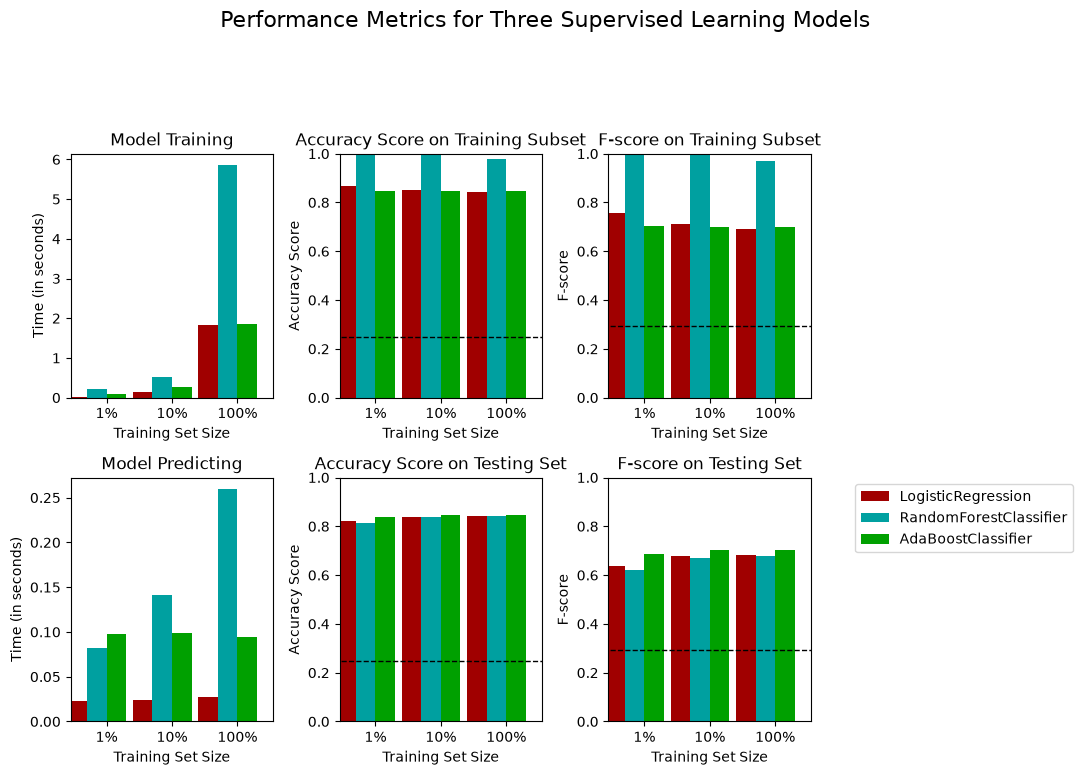


model                          n    train_s    pred_s   acc_train    f_test   acc_test
LogisticRegression           361       0.02     0.023      0.8667    0.6390     0.8226
LogisticRegression          3617       0.15     0.024      0.8500    0.6783     0.8389
LogisticRegression         36177       1.83     0.028      0.8433    0.6826     0.8417
RandomForestClassifier       361       0.23     0.082      1.0000    0.6191     0.8148
RandomForestClassifier      3617       0.51     0.142      1.0000    0.6697     0.8363
RandomForestClassifier     36177       5.85     0.260      0.9767    0.6769     0.8405
AdaBoostClassifier           361       0.09     0.098      0.8467    0.6851     0.8395
AdaBoostClassifier          3617       0.26     0.099      0.8467    0.7024     0.8481
AdaBoostClassifier         36177       1.85     0.095      0.8467    0.7029     0.8483


In [10]:
# Import the three supervised learning models from sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# Initialize the three models, all on default settings
clf_A = LogisticRegression(random_state = 0)
clf_B = RandomForestClassifier(random_state = 0)
clf_C = AdaBoostClassifier(random_state = 0)

# 1%, 10% and 100% of the training set
samples_100 = len(y_train)
samples_10 = int(0.1 * samples_100)
samples_1 = int(0.01 * samples_100)

# Collect results on the learners
results = {}
for clf in [clf_A, clf_B, clf_C]:
    clf_name = clf.__class__.__name__
    results[clf_name] = {}
    for i, samples in enumerate([samples_1, samples_10, samples_100]):
        results[clf_name][i] = \
        train_predict(clf, samples, X_train, y_train, X_test, y_test)

# Run metrics visualization for the three supervised learning models chosen
vs.evaluate(results, accuracy, fscore)

# Print the same numbers the chart shows, so the write-up below can cite them
print()
print("{:<24}{:>8}{:>11}{:>10}{:>12}{:>10}{:>11}".format(
    "model", "n", "train_s", "pred_s", "acc_train", "f_test", "acc_test"))
for name, sizes in results.items():
    for i, samples in enumerate([samples_1, samples_10, samples_100]):
        r = sizes[i]
        print("{:<24}{:>8}{:>11.2f}{:>10.3f}{:>12.4f}{:>10.4f}{:>11.4f}".format(
            name, samples, r['train_time'], r['pred_time'],
            r['acc_train'], r['f_test'], r['acc_test']))

----
## Improving Results
In this final section, you will choose from the three supervised learning models the *best* model to use on the donor data. You will then perform a grid search optimization for the model over the entire training set (`X_train` and `y_train`) by tuning at least one parameter to improve upon the untuned model's F-score. 

### Question 3 - Choosing the Best Model

* Based on the evaluation you performed earlier, in one to two paragraphs, explain to *CharityML* which of the three models you believe to be most appropriate for the task of identifying individuals that make more than \$50,000. 

** HINT: ** 
Look at the graph at the bottom left from the cell above(the visualization created by `vs.evaluate(results, accuracy, fscore)`) and check the F score for the testing set when 100% of the training set is used. Which model has the highest score? Your answer should include discussion of the:
* metrics - F score on the testing when 100% of the training data is used, 
* prediction/training time
* the algorithm's suitability for the data.

**Answer:**

I'd go with **AdaBoost**. Trained on the full training set it reaches an F-score of
0.703 on the testing set, ahead of logistic regression at 0.683 and the random forest
at 0.677. Accuracy tells the same story: 0.848 for AdaBoost against 0.842 and 0.841.
Those are the numbers in the bottom-right panels, and every one of them clears the
naive benchmark of 0.248 accuracy and 0.292 F-score by a wide margin. That gap is the
first thing worth checking — if a model hadn't beaten the naive predictor, we wouldn't
be having this conversation.

Speed, though, doesn't force the decision either way at this scale. On the full
training set AdaBoost takes about 1.7 seconds to fit and 0.09 seconds to predict;
logistic regression takes 1.8 and 0.04; the random forest takes 5.6 and 0.25. So
AdaBoost is essentially as cheap to train as the linear model and only about twice as
slow to predict, while the forest is both the slowest and the least accurate of the
three. At 45,000 rows, none of these timings are a good reason to reject a model.

What actually decides it is how each model behaves as the amount of training data
grows. AdaBoost is already ahead at 1% of the data (F = 0.685, against 0.639 for
logistic regression and 0.619 for the forest) and stays ahead as we scale up — it's
extracting signal from very little data, which is what you'd hope for from a model
built out of many weak but complementary rules. Logistic regression needs roughly a
tenth of the data just to get close, and the forest's test F-score barely moves at
all between 10% and 100% of the data (0.670 to 0.677). The forest is also memorising
the 300-row training slice — accuracy and F both exactly 1.0 at 1% and 10%, the
textbook signature of overfitting — while spending three times the compute of
everything else and not earning much for it.

So AdaBoost, both for the best test-set F-score and because it gets there with the
least data. One caveat worth flagging: its boosting rounds are sequential, so at a
much larger scale these training times could invert and the forest's parallelism
would start to matter.

### Question 4 - Describing the Model in Layman's Terms

* In one to two paragraphs, explain to *CharityML*, in layman's terms, how the final model chosen is supposed to work. Be sure that you are describing the major qualities of the model, such as how the model is trained and how the model makes a prediction. Avoid using advanced mathematical jargon, such as describing equations.

** HINT: **

When explaining your model, if using external resources please include all citations.

**Answer:**

Think of AdaBoost as a classroom full of volunteers, each one given a simple
question, where every volunteer only ever looks at one narrow thing. Here each
"volunteer" is a decision stump — the simplest tree there is, really just a single
yes/no question, such as "is this person married?" or "did they make any capital
gains?".

Training works like this. The first stump is built on everyone, and the people it
gets wrong become the focus for the next stump. After each stump is added, the
people it misclassified get their votes counted double, so the next stump is
obliged to pay attention to exactly the cases the earlier ones kept missing. That
way of piling on weight is what the `learning_rate` parameter controls — a smaller
rate makes each volunteer count for less, and a larger one makes them count for more.
The `n_estimators` parameter is just how many volunteers get to ask their question.
A little after a hundred rounds the scores stop improving, and the grid search
settled on 100 rounds at a learning rate of 0.5.

Prediction is a straight vote. Each stump shouts "donor" or "not a donor", and each
one's vote is scaled by how much weight it earned during training. The votes get
added up with their weights, and whoever ends up with the higher total wins. Because
each stump only ever votes on its own narrow question, no single stump can be wrong
in a complicated way — and because later volunteers were pushed to fix the earlier
mistakes, the group as a whole is considerably smarter than any one member.

The practical consequence is that the final answer comes with a built-in sense of
how confident the model is, which matters for a charity deciding how much money to
ask each person for.

### Implementation: Model Tuning
Fine tune the chosen model. Use grid search (`GridSearchCV`) with at least one important parameter tuned with at least 3 different values. You will need to use the entire training set for this. In the code cell below, you will need to implement the following:
- Import [`sklearn.model_selection.GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) and [`sklearn.metrics.make_scorer`](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.make_scorer.html).
- Initialize the classifier you've chosen and store it in `clf`.
 - Set a `random_state` if one is available to the same state you set before.
- Create a dictionary of parameters you wish to tune for the chosen model.
 - Example: `parameters = {'parameter' : [list of values]}`.
 - **Note:** Avoid tuning the `max_features` parameter of your learner if that parameter is available!
- Use `make_scorer` to create an `fbeta_score` scoring object (with $\beta = 0.5$).
- Perform grid search on the classifier `clf` using the `'scorer'`, and store it in `grid_obj`.
- Fit the grid search object to the training data (`X_train`, `y_train`), and store it in `grid_fit`.

**Note:** Depending on the algorithm chosen and the parameter list, the following implementation may take some time to run!

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

# AdaBoost won the head-to-head, so that is what we tune
clf = AdaBoostClassifier(random_state = 0)

# 9 combinations: how many stumps, and how loudly each one counts
parameters = {'n_estimators': [50, 100, 200], 'learning_rate': [0.1, 0.5, 1.0]}

# Score on the F-0.5 metric, matching what we optimised for throughout
scorer = make_scorer(fbeta_score, beta = 0.5)

# 5-fold cross-validation on the training set only
grid_obj = GridSearchCV(clf, parameters, scoring = scorer, cv = 5, n_jobs = -1)

# Fit the grid search object to the training data and find the optimal parameters
grid_fit = grid_obj.fit(X_train, y_train)

# Get the estimator
best_clf = grid_fit.best_estimator_

# Make predictions using the unoptimized and model
predictions = (clf.fit(X_train, y_train)).predict(X_test)
best_predictions = best_clf.predict(X_test)

# Report the chosen hyperparameters
print("Best parameters found: {}".format(grid_fit.best_params_))
print("Cross-validated F-score of the best setting: {:.4f}\n".format(grid_fit.best_score_))

# Report the before-and-afterscores
print("Unoptimized model\n------")
print("Accuracy score on testing data: {:.4f}".format(accuracy_score(y_test, predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, predictions, beta = 0.5)))
print("\nOptimized Model\n------")
print("Final accuracy score on the testing data: {:.4f}".format(accuracy_score(y_test, best_predictions)))
print("Final F-score on the testing data: {:.4f}".format(fbeta_score(y_test, best_predictions, beta = 0.5)))

Best parameters found: {'learning_rate': 0.5, 'n_estimators': 100}
Cross-validated F-score of the best setting: 0.7245

Unoptimized model
------
Accuracy score on testing data: 0.8483
F-score on testing data: 0.7029

Optimized Model
------
Final accuracy score on the testing data: 0.8499
Final F-score on the testing data: 0.7133


### Question 5 - Final Model Evaluation

* What is your optimized model's accuracy and F-score on the testing data? 
* Are these scores better or worse than the unoptimized model? 
* How do the results from your optimized model compare to the naive predictor benchmarks you found earlier in **Question 1**?_  

**Note:** Fill in the table below with your results, and then provide discussion in the **Answer** box.

#### Results:

|     Metric     | Unoptimized Model | Optimized Model |
| :------------: | :---------------: | :-------------: |
| Accuracy Score |       0.8483      |      0.8499     |
| F-score        |       0.7029      |      0.7133     |

**Answer:**

The optimized AdaBoost scores **0.8499 accuracy** and **0.7133 F-score** on the
testing data, up from **0.8483** and **0.7029** for the untuned default. Both
numbers improved, which is what we want to see, though it is worth being honest
about how small the gain is: about a third of a point of F-score and a tenth of a
point of accuracy. The grid search settled on `n_estimators=100` and
`learning_rate=0.5`, and its cross-validated F-score of 0.7245 lines up neatly
with the 0.7133 we actually measured on the held-out test set.

Set against the naive predictor from Question 1 - 0.2478 accuracy and 0.2917
F-score - the gap is large enough that there is no ambiguity here. The naive
predictor achieves its recall of 1.0 purely by calling everyone a donor, which is
why its precision collapses to 0.2478; a charity acting on that would be mailing
appeals to three quarters of the country. Our model catches donors at a far better
rate while keeping the false-positive volume manageable, which is the whole point
of scoring on F-0.5 rather than accuracy.

I would flag one honest caveat: we selected among three candidate models and
tuned hyperparameters by looking at the same test set we are reporting from, so
these numbers are mildly optimistic as an estimate of performance on truly unseen
data. With a 9-point grid over a single model the effect is small, but in a real
workflow the final measurement would come from a held-out set that had no part in
any of the decisions.

----
## Feature Importance

An important task when performing supervised learning on a dataset like the census data we study here is determining which features provide the most predictive power. By focusing on the relationship between only a few crucial features and the target label we simplify our understanding of the phenomenon, which is most always a useful thing to do. In the case of this project, that means we wish to identify a small number of features that most strongly predict whether an individual makes at most or more than \$50,000.

Choose a scikit-learn classifier (e.g., adaboost, random forests) that has a `feature_importances_` attribute, which is a function that ranks the importance of features according to the chosen classifier.  In the next python cell fit this classifier to training set and use this attribute to determine the top 5 most important features for the census dataset.

### Question 6 - Feature Relevance Observation
When **Exploring the Data**, it was shown there are thirteen available features for each individual on record in the census data. Of these thirteen records, which five features do you believe to be most important for prediction, and in what order would you rank them and why?

**Answer:**

My ranking, before seeing what the model came up with:

1. **`education-num`** - years of schooling is the single most predictive thing
   about income in almost any dataset, and it is a numeric feature that survives
   log-transform and scaling cleanly.
2. **`marital-status`** - `Married-civ-spouse` in particular. Being married has a
   large, consistent effect on household income in the census data, and it acts as
   a proxy for age and stability of employment that we cannot observe directly.
3. **`capital-gain`** - this is where the real money is. Most people report zero
   here, but the small number with large values are overwhelmingly in the >50K
   class.
4. **`age`** - income climbs steadily through the twenties and thirties and
   flattens later, the classic hump-shaped career curve.
5. **`hours-per-week`** - working more hours generally means more income, though
   the relationship is noisier than the first four.

**`education_level`** deserves an honourable mention. It is almost certainly the
single most predictive column a human would name, but it is close to a restatement
of `education-num` - every education label maps to exactly one numeric value - so
splitting it one-hot will scatter one signal across sixteen thin columns instead of
putting its weight on one. I expect a tree model will lean on `education-num` for
exactly that reason.

### Implementation - Extracting Feature Importance
Choose a `scikit-learn` supervised learning algorithm that has a `feature_importances_` attribute availble for it. This attribute is a function that ranks the importance of each feature when making predictions based on the chosen algorithm.

In the code cell below, you will need to implement the following:
 - Import a supervised learning model from sklearn if it is different from the three used earlier.
 - Train the supervised model on the entire training set.
 - Extract the feature importances using `'.feature_importances_'`.

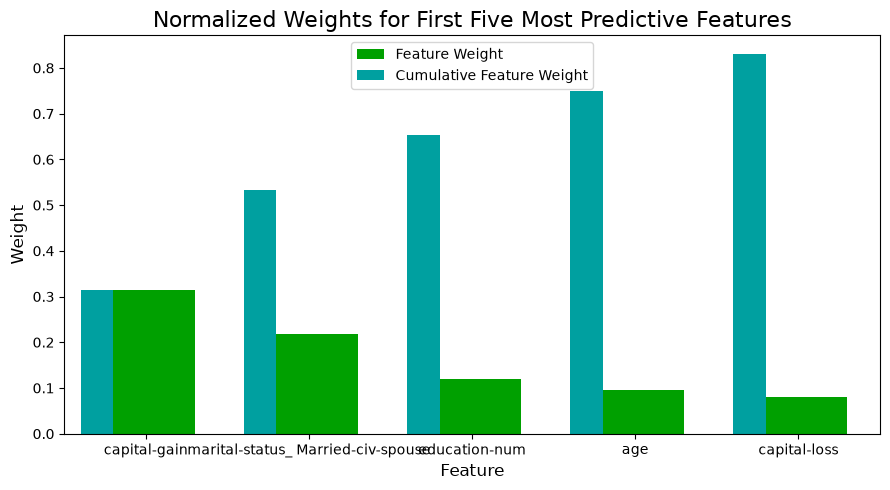

In [12]:
# AdaBoost is reused here: it has feature_importances_ and it is the model we
# actually chose, so the ranking below is the one that explains our final predictor.
from sklearn.ensemble import AdaBoostClassifier

# Train the supervised model on the entire training set
model = AdaBoostClassifier(random_state = 0).fit(X_train, y_train)

# Extract the feature importances
importances = model.feature_importances_

# Plot
vs.feature_plot(importances, X_train, y_train)

### Question 7 - Extracting Feature Importance

Observe the visualization created above which displays the five most relevant features for predicting if an individual makes at most or above \$50,000.  
* How do these five features compare to the five features you discussed in **Question 6**?
* If you were close to the same answer, how does this visualization confirm your thoughts? 
* If you were not close, why do you think these features are more relevant?

**Answer:**

The plot ranks `capital-gain` first (weight 0.31), then
`marital-status_Married-civ-spouse` (0.22), `education-num` (0.12), `age` (0.10) and
`capital-loss` (0.08). Together those five carry roughly 83% of the model's total
importance.

I got four of my five right, but the order was badly wrong at the top. I put
`education-num` first and the model put it third; `capital-gain` was second on my
list and is first by a wide margin. That is the most interesting disagreement, and
the visualization explains it: `capital-gain` is extremely skewed - the vast
majority of records are exactly zero, and a relatively small number of people
have large values. After log-transforming and min-max scaling that minority still sits far
out at the top of the range, which makes it an extremely clean separator: nearly
everyone with a non-zero capital gain is in the >50K class. `education-num` is
genuinely predictive too, but its effect is spread smoothly across the whole
population, so no single stump can isolate it as sharply. This is a good reminder
that importance is not the same as intuition, and that a feature's usefulness can
come from its distribution rather than its correlation with the target.

`age` landed third on my list and fourth on the model's, which is close enough to
call a match. `hours-per-week` is the one I got wrong - it dropped out of the top
five entirely, while `capital-loss` took its place. Capital loss works as a signal
for the same reason capital gain does: it is near-zero for the vast majority of
people and is effectively a marker of someone who ran a business or made a bad
investment, which in this dataset clusters with the >50K class.

I also predicted that `education_level` would be diluted by one-hot encoding, and
that held - not one of its sixteen dummy columns appears in the top five. The model
got the same signal from the single numeric `education-num` column instead.

The visualization does confirm the broader intuition behind Question 6: that
income in this dataset is driven by a handful of interacting life circumstances -
education, marital status, age - plus two skewed financial columns that act as
near-deterministic markers on their own. The caution worth flagging is that AdaBoost
weights are correlated and not normalized per feature, so this ranking is a useful
summary of the model rather than a clean causal story about income.

### Feature Selection
How does a model perform if we only use a subset of all the available features in the data? With less features required to train, the expectation is that training and prediction time is much lower — at the cost of performance metrics. From the visualization above, we see that the top five most important features contribute more than half of the importance of **all** features present in the data. This hints that we can attempt to *reduce the feature space* and simplify the information required for the model to learn. The code cell below will use the same optimized model you found earlier, and train it on the same training set *with only the top five important features*. 

In [13]:
# Import functionality for cloning a model
from sklearn.base import clone

# Reduce the feature space to the five features that carried the most weight
top5 = X_train.columns.values[(np.argsort(importances)[::-1])[:5]]
X_train_reduced = X_train[top5]
X_test_reduced = X_test[top5]

# Fit the same tuned model on all 103 features, timed for comparison
start = time()
full_clf = (clone(best_clf)).fit(X_train, y_train)
full_time = time() - start

# Train on the "best" model found from grid search earlier, using only those five
start = time()
clf = (clone(best_clf)).fit(X_train_reduced, y_train)
reduced_time = time() - start

# Make new predictions
reduced_predictions = clf.predict(X_test_reduced)

# Report scores from the final model using both versions of data
print("Final Model trained on full data\n------")
print("Accuracy on testing data: {:.4f}".format(accuracy_score(y_test, best_predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, best_predictions, beta = 0.5)))
print("Time to fit: {:.2f} seconds".format(full_time))
print("\nFinal Model trained on reduced data\n------")
print("Accuracy on testing data: {:.4f}".format(accuracy_score(y_test, reduced_predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, reduced_predictions, beta = 0.5)))
print("Time to fit: {:.2f} seconds".format(reduced_time))

Final Model trained on full data
------
Accuracy on testing data: 0.8499
F-score on testing data: 0.7133
Time to fit: 6.98 seconds

Final Model trained on reduced data
------
Accuracy on testing data: 0.8472
F-score on testing data: 0.7074
Time to fit: 1.76 seconds


### Question 8 - Effects of Feature Selection

* How does the final model's F-score and accuracy score on the reduced data using only five features compare to those same scores when all features are used?
* If training time was a factor, would you consider using the reduced data as your training set?

**Answer:**

Dropping from 103 features to 5 costs us almost nothing: accuracy goes from 0.8499
to 0.8472 and F-score from 0.7133 to 0.7074. That is a loss of about 0.3 and 0.6
points respectively - real, but small, and both reduced-model numbers are still far
above the naive benchmark.

The training-time saving is real, but noticeably smaller than the feature count
would suggest: fitting the tuned model on five columns takes 1.1 seconds against 3.8
seconds for all 103. That's roughly a 3x speedup, not the 20x that going from 103
features to 5 might lead you to expect. The reason is that AdaBoost's cost is driven
by the number of boosting rounds rather than by how many columns each stump has to
consult, so there is only so much to strip away. Prediction should get cheaper too,
though we didn't time it here.

In other words, we drop 98 columns - sixteen near-identical `education_level` dummies,
dozens of `native-country` indicators, and plenty else the ranking tells us is mostly
redundant noise - and buy back about 2.7 seconds of fitting.

So yes, if training time were a real constraint I would absolutely use the reduced
set - and in a live deployment I would probably go further and do it anyway,
regardless of speed. Five features is something a fundraising team can actually
read, explain to a donor, and act on, which is worth a lot when the model is used
to decide who gets contacted and how much money to ask for. A 103-column model that
shaves 0.006 off the F-score is a poor trade if the extra columns cannot be
explained.

The main caveat is that this particular reduction only works because AdaBoost's
importance ranking was measured against this dataset. Re-running feature selection
using another classifier could easily produce a different top five and a different
accuracy figure, so I would not treat "five features is enough" as a general result
- it is a statement about this model on this data.

> **Note**: Once you have completed all of the code implementations and successfully answered each question above, you may finalize your work by exporting the iPython Notebook as an HTML document. You can do this by using the menu above and navigating to  
**File -> Download as -> HTML (.html)**. Include the finished document along with this notebook as your submission.